In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
X_fantoma = np.array([
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
[0.0, 0.0, 0.8, 0.3, 0.3, 0.3, 0.0, 0.0],
[0.0, 0.8, 0.8, 0.8, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.8, 0.3, 0.3, 0.3, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.3, 0.5, 0.3, 0.0],
[0.0, 0.3, 0.3, 0.3, 0.5, 0.5, 0.5, 0.0],
[0.0, 0.0, 0.3, 0.3, 0.3, 0.5, 0.0, 0.0],
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
], dtype=float)

In [3]:
x_fantoma = X_fantoma.reshape(-1)

In [4]:
# Devuelve la matriz A: cada fila es un rayo (su máscara vectorizada por filas),
# cada columna un píxel. Los rayos van agrupados por dirección y ordenados por s.
def matriz_proyeccion(n, direcciones):
  res = []

  for direccion in direcciones:                                      # Por cada dirección (α, β)
    eses = []                                                        # Valores de s de esa dirección

    for i in range(n):                                               # Por cada fila
      for j in range(n):                                             # Por cada columna
        s = direccion[0] * i + direccion[1] * j                      # El s del rayo que pasa por ese píxel

        if s not in eses:                                            # Evitamos repetir rayos
          eses.append(s)

    for s in sorted(eses):                                           # Por cada rayo, de menor a mayor s
      res.append(mascara_rayo(n, direccion, s).reshape(-1))          # Agregamos su máscara vectorizada

  return np.array(res)

In [5]:
def mascara_rayo(n, direccion, s):
  res = np.zeros((n, n))                                             # Inicializamos una matriz de ceros
  for i in range(0, n):                                              # Por cada fila
    for j in range(0, n):                                            # Por cada columna
      if direccion[0] * i + direccion[1] * j == s:                   # Vemos si está en el centro
        res[i, j] = 1                                                # Modificamos

  return res

a) Para que la imagen pueda reconstruirse de manera única, el rango(A) debe ser igual a las columnas de A.

En la clase de espacios vectoriales, definimos que si una matriz tiene $n$ columnas, entonces:

$$\text{rango}(A) + \dim(\text{Nul}(A)) = n$$

$\dim(\text{Nul}(A))$ es igual a la cantidad de variables libres. Entonces si yo tengo 0 variables libres, significa que $\text{rango}(A) = n$. O sea, voy a tener $n$ pivotes y la solución va a ser única.

Si existe un vector no nulo $v$ tal que $Av = 0$, entonces esto quiere decir que el sistema homogéneo tiene infinitas soluciones además de la trivial. Esto es un problema para la reconstrucción: si $x$ es una imagen tal que $Ax = b$, entonces $x + v$ también cumple $A(x + v) = Ax + Av = b$, o sea que dos imágenes distintas producen exactamente las mismas mediciones. A partir de $b$ no se puede distinguir cuál de las dos es la imagen real.

Esto se relaciona con rango(A) y $\dim(\text{Nul}(A))$ porque la existencia de ese $v \neq 0$ significa que $\dim(\text{Nul}(A)) \geq 1$, y por el teorema de rango y nulidad eso implica $\text{rango}(A) < n$. O sea que si hay un $v$ no nulo en el núcleo de A, el rango no llega a ser $n$, y la reconstrucción no es única.

b)

In [9]:
n=8
dir_2 = [(1,0), (0,1)]
dir_4 = [(1,0), (0,1), (1,1), (1,-1)]
dir_7 = [(1,0), (0,1), (1,1), (1,-1), (2,1), (1,2), (3,1)]

A_2 = matriz_proyeccion(n, dir_2)
A_4 = matriz_proyeccion(n, dir_4)
A_7 = matriz_proyeccion(n, dir_7)

for nombre, A in [("A2", A_2), ("A4", A_4), ("A7", A_7)]:
  m, n_cols = A.shape
  rango = np.linalg.matrix_rank(A)                                      # Rango de la matriz
  nulidad = n_cols - rango                                             # Teorema de rango y nulidad del inciso a)

  print(f"{nombre}: dimensiones {A.shape}")
  print(f"  rango(A) = {rango}")
  print(f"  dim(Nul(A)) = {nulidad}")
  print(f"  ¿reconstrucción única? {rango == n_cols}")
  print(f"  mediciones redundantes = {m - rango}")                      # Una medición redundante es una fila de A (un rayo)
                                                                        # cuya información ya está contenida en las demás filas —
                                                                        # no suma nada nuevo para determinar la imagen, aunque físicamente sea un rayo distinto.

A2: dimensiones (16, 64)
  rango(A) = 15
  dim(Nul(A)) = 49
  ¿reconstrucción única? False
  mediciones redundantes = 1
A4: dimensiones (46, 64)
  rango(A) = 39
  dim(Nul(A)) = 25
  ¿reconstrucción única? False
  mediciones redundantes = 7
A7: dimensiones (119, 64)
  rango(A) = 64
  dim(Nul(A)) = 0
  ¿reconstrucción única? True
  mediciones redundantes = 55


c)

In [11]:
A_4 = matriz_proyeccion(8, dir_4)

U, S, Vt = np.linalg.svd(A_4)                                        # Vt tiene por filas los v_i
rango = np.linalg.matrix_rank(A_4)

v = Vt[-1]                                                           # Dirección del espacio nulo

print(f"A_4 ∈ R^{A_4.shape}, rango = {rango}, dim(Nul) = {64 - rango}")
print(f"||v|| = {np.linalg.norm(v):.4f}")                            # No nulo
print(f"||A_4 v|| = {np.linalg.norm(A_4 @ v):.2e}")                  # Aproximadamente 0

A_4 ∈ R^(46, 64), rango = 39, dim(Nul) = 25
||v|| = 1.0000
||A_4 v|| = 1.23e-15


||A_4 x_alt - b_4|| = 9.94e-16
||x_alt - x_fantoma|| = 1.0000


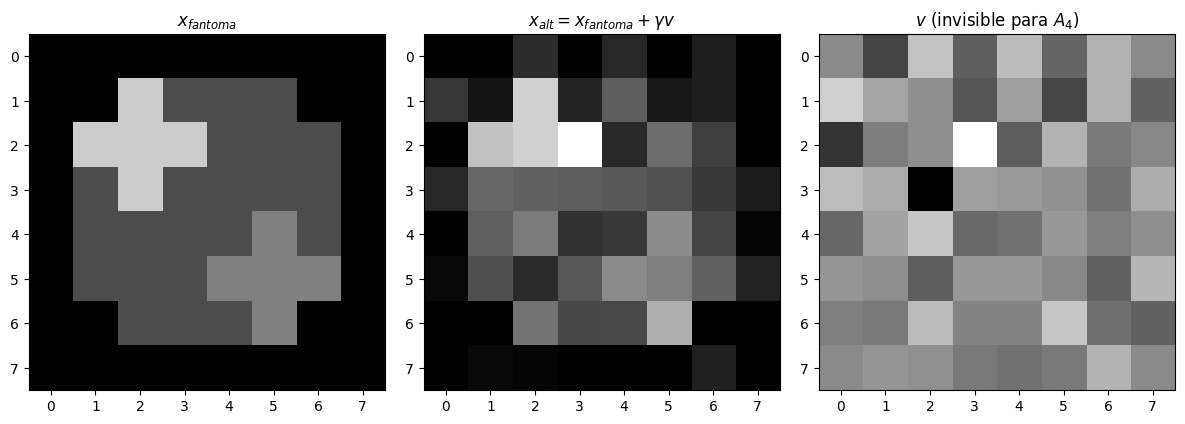

In [29]:
gamma = 1.0                                                          # Hiperparámetro de regularización

b_4 = A_4 @ x_fantoma
x_alt = x_fantoma + gamma * v                                        # Imagen alternativa

print(f"||A_4 x_alt - b_4|| = {np.linalg.norm(A_4 @ x_alt - b_4):.2e}")     # Mismas mediciones
print(f"||x_alt - x_fantoma|| = {np.linalg.norm(x_alt - x_fantoma):.4f}")   # Imágenes distintas

fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(x_fantoma.reshape(8, 8), cmap='gray', vmin=0, vmax=1)
ax[0].set_title("$x_{fantoma}$")

ax[1].imshow(x_alt.reshape(8, 8), cmap='gray', vmin=0, vmax=1)
ax[1].set_title("$x_{alt} = x_{fantoma} + \\gamma v$")

ax[2].imshow(v.reshape(8, 8), cmap='gray')
ax[2].set_title("$v$ (invisible para $A_4$)")

plt.tight_layout()
plt.show()

In [15]:
V = v.reshape(8, 8)

print(np.abs(V.sum(axis=1)).max())                                   # Sumas por filas: ~0
print(np.abs(V.sum(axis=0)).max())                                   # Sumas por columnas: ~0

4.996003610813204e-16
4.996003610813204e-16


$A_4$ solo mide sumas a lo largo de cuatro direcciones: filas, columnas y las dos diagonales. Toda la información que sobrevive en $b_4$ son esos totales. Lo que resulta invisible es cualquier patrón que redistribuya los valores dentro de cada fila, cada columna y cada diagonal sin alterar sus sumas, y eso es exactamente lo que caracteriza al espacio nulo: $v$ cumple que sus sumas por filas, por columnas y por ambas diagonales son todas nulas, así que sumárselo a la imagen no modifica ninguna medición.

Como $\dim(\text{Nul}(A_4)) = 25$, lo invisible no es un patrón aislado sino un subespacio de dimensión 25 dentro de los 64 grados de libertad de la imagen. $A_4$ determina únicamente la componente de la imagen en el complemento ortogonal, de dimensión 39 (el rango). Las otras 25 dimensiones quedan completamente indeterminadas: cualquier valor que tomen produce el mismo $b_4$.

El gráfico lo muestra: $x_{alt}$ es visiblemente distinta de $x_{fantoma}$ — el contorno del fantoma desapareció y el fondo dejó de ser uniforme — y aun así $\|A_4 x_{alt} - b_4\| \approx 10^{-15}$. A partir de las mediciones no hay forma de saber cuál de las dos era el objeto real, ni ninguna otra de la familia infinita $x_{fantoma} + \gamma v$.